### The 10-qubit quantum circuit measuring relaxation time anomalies

The idea behind the first circuit is simple. Excite all ten qubits at once, wait a delay much shorter than their natural relaxation time, then ask each of them whether it is still excited. Almost all should say 'yes'. If instead a large number say no, simultaneously, and go on saying no for several consecutive rounds, something has happened to the whole chip rather than to any one qubit. It is the difference between a single smoke alarm going off and every alarm in the building screaming in concert.

As a quick recap, the relaxation time $T_1$ gives the probability of measuring the state $|1\rangle$ after a time $t$ has passed from the excitation:
$$P(|1\rangle) = \mathrm{e}^{-\frac{t}{T_{1}}}.$$

In [1]:
import json
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from qiskit import QuantumCircuit, QuantumRegister

In [2]:
qreg = QuantumRegister(10)
circuit = QuantumCircuit(qreg) 

for n in range(5): 

    for qubit in qreg:
        circuit.x(qubit)

    circuit.barrier()

    for qubit in qreg:
        circuit.delay(2, qubit, "us") 

    circuit.measure_all()

    circuit.barrier()

    for qubit in qreg:
        circuit.delay(1, qubit, "ms") 

    circuit.barrier()


for qubit in qreg:
        circuit.x(qubit)
circuit.barrier()

for qubit in qreg:
        circuit.delay(2, qubit, "us") 

circuit.measure_all()

print(circuit)

          ┌───┐ ░ ┌──────────────┐ ░ ┌─┐                            ░ »
    q0_0: ┤ X ├─░─┤ Delay(2[us]) ├─░─┤M├────────────────────────────░─»
          ├───┤ ░ ├──────────────┤ ░ └╥┘┌─┐                         ░ »
    q0_1: ┤ X ├─░─┤ Delay(2[us]) ├─░──╫─┤M├─────────────────────────░─»
          ├───┤ ░ ├──────────────┤ ░  ║ └╥┘┌─┐                      ░ »
    q0_2: ┤ X ├─░─┤ Delay(2[us]) ├─░──╫──╫─┤M├──────────────────────░─»
          ├───┤ ░ ├──────────────┤ ░  ║  ║ └╥┘┌─┐                   ░ »
    q0_3: ┤ X ├─░─┤ Delay(2[us]) ├─░──╫──╫──╫─┤M├───────────────────░─»
          ├───┤ ░ ├──────────────┤ ░  ║  ║  ║ └╥┘┌─┐                ░ »
    q0_4: ┤ X ├─░─┤ Delay(2[us]) ├─░──╫──╫──╫──╫─┤M├────────────────░─»
          ├───┤ ░ ├──────────────┤ ░  ║  ║  ║  ║ └╥┘┌─┐             ░ »
    q0_5: ┤ X ├─░─┤ Delay(2[us]) ├─░──╫──╫──╫──╫──╫─┤M├─────────────░─»
          ├───┤ ░ ├──────────────┤ ░  ║  ║  ║  ║  ║ └╥┘┌─┐          ░ »
    q0_6: ┤ X ├─░─┤ Delay(2[us]) ├─░──╫──╫──╫──╫──╫──╫─┤M├──────

### The 14-qubit quantum circuit measuring relaxation time anomalies with Ramsey-style extension

In [3]:
#we set a fixed value for detuning frequencies
#these could be changed to a device specific values if the required data is available
#therefore this code is created so that in theory the detuning frequencies could be different

detuning_frequencies = np.array([1.0, 1.0, 1.0, 1.0]) 

delay_4 = [float(1.0/(f*4.0)) for f in detuning_frequencies]

Delay_4max = max(delay_4) #us
Delay_3min = 1.960 - Delay_4max #us

d_n = [Delay_4max - x for x in delay_4]
delay_3 = [Delay_3min + x for x in d_n]

qreg = QuantumRegister(14) #0-9 for T1 10-13 for Ramsey
circuit = QuantumCircuit(qreg)

for n in range(6):

    for i in range(14):
        if i < 10:
            circuit.x(qreg[i])
        else:
            circuit.delay(20, qreg[i], "ns")

    circuit.barrier()

    for i in range(14):
        if i < 10:
            circuit.delay(Delay_3min, qreg[i], "us")
        else:
            circuit.delay(delay_3[i-10], qreg[i], "us")
            

    for i in range(14):
        if i < 10:
            circuit.delay(20, qreg[i], "ns")
        else:
            circuit.ry(math.pi/2, qreg[i])


    for i in range(14):
        if i < 10:
            circuit.delay(Delay_4max, qreg[i], "us")
        else:
            circuit.delay(delay_4[i-10], qreg[i], "us")
            
    circuit.barrier()


    for i in range(14):
        if i < 10:
            circuit.delay(20, qreg[i], "ns")
        else:
            circuit.rx(math.pi/2, qreg[i])
            

    circuit.measure_all()

    if n < 5:
        circuit.barrier()

        for i in range(14):
            circuit.delay(1, qreg[i], "ms")

        circuit.barrier()    

print(circuit)

                ┌───┐       ░ ┌─────────────────┐┌───────────────┐»
    q1_0: ──────┤ X ├───────░─┤ Delay(1.71[us]) ├┤ Delay(20[ns]) ├»
                ├───┤       ░ ├─────────────────┤├───────────────┤»
    q1_1: ──────┤ X ├───────░─┤ Delay(1.71[us]) ├┤ Delay(20[ns]) ├»
                ├───┤       ░ ├─────────────────┤├───────────────┤»
    q1_2: ──────┤ X ├───────░─┤ Delay(1.71[us]) ├┤ Delay(20[ns]) ├»
                ├───┤       ░ ├─────────────────┤├───────────────┤»
    q1_3: ──────┤ X ├───────░─┤ Delay(1.71[us]) ├┤ Delay(20[ns]) ├»
                ├───┤       ░ ├─────────────────┤├───────────────┤»
    q1_4: ──────┤ X ├───────░─┤ Delay(1.71[us]) ├┤ Delay(20[ns]) ├»
                ├───┤       ░ ├─────────────────┤├───────────────┤»
    q1_5: ──────┤ X ├───────░─┤ Delay(1.71[us]) ├┤ Delay(20[ns]) ├»
                ├───┤       ░ ├─────────────────┤├───────────────┤»
    q1_6: ──────┤ X ├───────░─┤ Delay(1.71[us]) ├┤ Delay(20[ns]) ├»
                ├───┤       ░ ├─────────────────

### Error Profile

The error profile is based on the relaxation times of the qubits and the calibration data of the device the circuit is run on. We calculate upper and lower bound estimates for the probabilities of measuring zeros. In order to avoid false positives, we used the stricter version in our data analysis. However, depending on the context, one may also use the other.

The probability of measuring zero for an individual qubit is given by:
$$p(|0\rangle)=P(|0\rangle)(1-\epsilon(0\mapsto 1))+P(|1\rangle)\epsilon(1\mapsto 0)$$

Here:

$P(|0\rangle) = 1 - \mathrm{e}^{-\frac{t}{T_{1}}},$
which is the probability of measuring $|0\rangle$ after time $t$

$\epsilon(0\mapsto 1)$ = the read-out-error probability: $|0\rangle$ accidentally read as $|1\rangle$


$P(|1\rangle) = \mathrm{e}^{-\frac{t}{T_{1}}}$,
the probability of measuring $|1\rangle$

$\epsilon(1\mapsto 0)$ = the read-out-error probability: $|1\rangle$ accidentally read as $|0\rangle$







In the expression, we first take into account the possibility that the qubit really measured zero and is also correctly read, whereas the second term is for the case where the qubit is in the excited state but incorrectly read as zero. 

In [4]:
#the probability model in code
#an example layout
initial_layout = [2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]

#in microseconds
T1s = []
T1_errors = []

wait_time = 2 #the delay time t_1 used for the relaxation time monitoring qubits

#as percentages:
one_read_as_zero = []
one_read_as_zero_errors = []

zero_read_as_one = []
zero_read_as_one_errors = []

#read the json file containing current calibration data
#replace with your own data. The json file included is example and not up to date with the current calibration data of the device.
#the calibration data can be downloaded from https://fiqci.fi/status
with open("Q50_cal.json", "r") as f:
    calibration = json.load(f)


for i in initial_layout:
    n = i+1

    t1_data = calibration["metrics"]["t1_time"][f"QB{n}"]["value"]
    t1_val = t1_data * 1e6
    T1s.append(t1_val)

    error_t1 = calibration["metrics"]["t1_time"][f"QB{n}"]["uncertainty"]
    error_t1_val = error_t1 * 1e6
    T1_errors.append(error_t1_val)


    one_to_0 = calibration["metrics"]["measure_ssro_constant_error_1_to_0"][f"QB{n}"]["value"]
    one_to_0_val = one_to_0 * 100.0
    one_read_as_zero.append(one_to_0_val)

    error_1_to_0 = calibration["metrics"]["measure_ssro_constant_error_1_to_0"][f"QB{n}"]["uncertainty"]
    error_1_to_0_val = error_1_to_0 * 100.0
    one_read_as_zero_errors.append(error_1_to_0_val)

    zero_to_1 = calibration["metrics"]["measure_ssro_constant_error_0_to_1"][f"QB{n}"]["value"]
    zero_to_1_val = zero_to_1 * 100.0
    zero_read_as_one.append(zero_to_1_val)

    error_0_to_1 = calibration["metrics"]["measure_ssro_constant_error_0_to_1"][f"QB{n}"]["uncertainty"]
    error_0_to_1_val = error_0_to_1 * 100.0
    zero_read_as_one_errors.append(error_0_to_1_val)


#-------constructing the error profile---------------

def helper(T1s, T1_errors_abs, wait_time):
    up_T1s = np.array(T1s) + np.array(T1_errors_abs)
    low_T1s = np.array(T1s) - np.array(T1_errors_abs)


    up_decay_single = np.array([1.0-math.exp(-wait_time*1e-6 / (time*1e-6)) for time in low_T1s])
    low_decay_single = np.array([1.0-math.exp(-wait_time*1e-6 / (time*1e-6)) for time in up_T1s])

    return up_decay_single, low_decay_single


#returns lists with up error and low error
def helper_error(zero_one, zero_one_er, one_zero, one_zero_er):
    #for upper bound:

    S_zero_one = (np.array(zero_one) - np.array(zero_one_er))/100.0
    L_one_zero = (np.array(one_zero) + np.array(one_zero_er))/100.0

    upper_bound = [S_zero_one, L_one_zero]

    L_zero_one = (np.array(zero_one) + np.array(zero_one_er))/100.0
    S_one_zero = (np.array(one_zero) - np.array(one_zero_er))/100.0


    lower_bound = [L_zero_one, S_one_zero]


    return upper_bound, lower_bound


def single_prob_with_errors(T1s, T1_errors_abs, wait_time, zero_one, zero_one_er, one_zero, one_zero_er):
    
    #P(m=0) for single qubits
    up_decay_single, low_decay_single = helper(T1s, T1_errors_abs, wait_time)
    #epsilons
    upper_bounds_SL, lower_bounds_LS = helper_error(zero_one, zero_one_er, one_zero, one_zero_er)

    up_epsilon_zero_one, up_epsilon_one_zero = upper_bounds_SL[0], upper_bounds_SL[1]


    up_probs = (up_decay_single * (1 - up_epsilon_zero_one)
                + (1-up_decay_single) * up_epsilon_one_zero)


    low_epsilon_zero_one, low_epsilon_one_zero = lower_bounds_LS[0], lower_bounds_LS[1]    


    low_probs = (low_decay_single * (1 - low_epsilon_zero_one)
    + (1 - low_decay_single) * low_epsilon_one_zero)

    return up_probs, low_probs 


def decay_probabilities(T1s, T1_errors_abs, wait_time, zero_one, zero_one_er, one_zero, one_zero_er):
    
    #single qubit decay probabilities
    single_up, single_low = single_prob_with_errors(T1s, T1_errors_abs, wait_time, zero_one, zero_one_er, one_zero, one_zero_er) 

    qubit_num = len(T1s)

    up_prob = np.zeros(qubit_num + 1)
    low_prob = np.zeros(qubit_num + 1)

    up_prob[0] = 1.0
    low_prob[0] = 1.0

    for p_i in single_up:
        new_up_prob = np.zeros(qubit_num + 1)

        for k in range(qubit_num):
            new_up_prob[k] += up_prob[k] * (1 - p_i)
            new_up_prob[k+1] += up_prob[k] * p_i

        up_prob = new_up_prob

    for p_i in single_low:
        new_low_prob = np.zeros(qubit_num + 1)

        for k in range(qubit_num):
            new_low_prob[k] += low_prob[k] * (1 - p_i)
            new_low_prob[k+1] += low_prob[k] * p_i

        low_prob = new_low_prob


    return up_prob, low_prob


print(decay_probabilities(T1s, T1_errors, 2, zero_read_as_one, zero_read_as_one_errors, one_read_as_zero, one_read_as_zero_errors))

up_prob, low_prob = decay_probabilities(
    T1s,
    T1_errors,
    wait_time,
    zero_read_as_one,
    zero_read_as_one_errors,
    one_read_as_zero,
    one_read_as_zero_errors
)


# Conservative probability estimate
prob_exact = np.maximum(up_prob, low_prob)

# Tail probabilities:
# prob_tail[k] = P(K >= k)
prob_tail = np.cumsum(prob_exact[::-1])[::-1]


(array([1.41983356e-01, 3.00215644e-01, 2.91367966e-01, 1.72132393e-01,
       6.91854611e-02, 2.00205427e-02, 4.30255255e-03, 6.97732514e-04,
       8.58089764e-05, 7.96463954e-06, 5.49218894e-07, 2.72818611e-08,
       9.22708897e-10, 1.90150492e-11, 1.80086759e-13]), array([1.77457479e-01, 3.29337262e-01, 2.80557969e-01, 1.45472435e-01,
       5.13072447e-02, 1.30239058e-02, 2.45413833e-03, 3.48761018e-04,
       3.75622742e-05, 3.05096902e-06, 1.83951665e-07, 7.98213770e-09,
       2.35597213e-10, 4.23271453e-12, 3.49118464e-14]))


### Data analysis using the constructed probability model

In [5]:
#Creating a pandas dataframe from the measurement data
#Here, it is assumed that first 10 qubits of the quantum circuit are for the relaxation time monitoring
#and the last four qubits for Ramsey values

#add your data file. The provided data file is an example and not up to date with the current calibration data of the device.
#you can generate your own data file by running the circuit in the first part of this code and saving the result as a numpy file.
#instructions for running quantum jobs on FiQCI devices can be found from https://docs.csc.fi/computing/quantum-computing/overview/
data = np.load("T1_Ramsey_data.npy", allow_pickle=True)
result = data.item()

memory = result.get_memory()

rows_first4 = []
rows_last10 = []

for shot in memory:
    # Reverse measurement-round order so rounds[0] is m1, rounds[1] is m2, ...
    rounds = shot.split()[::-1]

    row_first4 = {}
    row_last10 = {}

    for i in range(6):
        bitstring = rounds[i]

        #Qiskit records the most significant qubits (last qubits in circuit diagrams) first
        row_first4[f"m{i+1}"] = bitstring[:4]   # bits 0-3
        row_last10[f"m{i+1}"] = bitstring[4:]   # bits 4-13

    rows_first4.append(row_first4) 
    rows_last10.append(row_last10)

# Create dataframes
df_first4 = pd.DataFrame(rows_first4)
df_last10 = pd.DataFrame(rows_last10)


print(df_first4.head()) #Ramsey dataframe
print(df_last10.head()) #T1 dataframe

     m1    m2    m3    m4    m5    m6
0  1110  0100  1111  1110  0110  1111
1  1101  0011  1001  0011  1100  0100
2  1110  0001  0110  0101  0101  0001
3  0110  1110  1110  1100  1010  1111
4  1100  0010  0011  1101  0011  0000
           m1          m2          m3          m4          m5          m6
0  1111111111  1111011101  1011111101  1111111101  1111111110  1111011111
1  1111111111  1111111111  1100111111  1111111111  1101101111  1111111111
2  1111111111  1011111111  1110111111  1111011011  1111111110  1110111111
3  1101111111  1111110011  1111111111  1111110111  0011111111  1111111111
4  1110111111  1101010111  1111111111  1101111111  1001111111  1111111111


/home/nivalajo/work/csc/Quantum/Sensing-Environmental-Error-Bursts/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [6]:
#See if there are any interesting events

def longest_zero_run(bitstring):
    longest = 0
    current = 0

    for bit in bitstring:
        if bit == "0":
            current += 1
            longest = max(longest, current)
        else:
            current = 0

    return longest


rows = []

for i, row in df_last10.iterrows():

    for r in ["m1", "m2", "m3", "m4", "m5", "m6"]:

        bitstring = row[r]

        rows.append({
            "shot": i,
            "round": r,
            "num_zeros": bitstring.count("0"),
            "max_zero_run": longest_zero_run(bitstring)
        })

long_df = pd.DataFrame(rows)
long_df["t"] = long_df.groupby("shot").cumcount()
round_map = {"m1": 0, "m2": 1, "m3": 2, "m4": 3, "m5": 4, "m6": 5}
long_df["t"] = long_df["round"].map(round_map) + long_df["shot"] * 6


#-------------finding consecutive errors---------------------
interesting_shots = []

for shot_idx, row in df_last10.iterrows():

    zero_counts = {
        m: row[m].count("0")
        for m in ["m1","m2","m3","m4","m5","m6"]
    }

    cond_1_6 = all(
        zero_counts[m] >= 3
        for m in ["m1","m2","m3","m4","m5","m6"]
    )

    cond_2_6 = all(
        zero_counts[m] >= 3
        for m in ["m2","m3","m4","m5","m6"]
    ) 


    cond_3_6 = all(
        zero_counts[m] >= 3
        for m in ["m3","m4","m5","m6"]
    ) 



    if cond_1_6 or cond_2_6 or cond_3_6:

        interesting_shots.append({
            "shot": shot_idx,
            "all_m1_to_m6": cond_1_6,
            "all_m2_to_m6": cond_2_6,
            "all_m3_to_m6": cond_3_6
        })

interesting_df = pd.DataFrame(interesting_shots)

print(f"Found {len(interesting_df)} interesting shots")

#----measurement rounds for every interesting shot----

for _, event in interesting_df.iterrows():

    shot = event["shot"]

    print("\n" + "=" * 70)
    print(f"Interesting shot: {shot}")

    if event["all_m1_to_m6"]:
        print("Condition satisfied: m1-m6 all contain at least 3 zeros")

    if event["all_m2_to_m6"]:
        print("Condition satisfied: m2-m6 all contain at least 3 zeros")

    
    if event["all_m3_to_m6"]:
        print("Condition satisfied: m3-m6 all contain at least 3 zeros")    

    print("\nMeasurement rounds:")

    shot_row = df_last10.loc[shot]

    for round_name in ["m1", "m2", "m3", "m4", "m5", "m6"]:

        bitstring = shot_row[round_name]

        zero_qubits = [
            q for q in range(10)
            if bitstring[9 - q] == "0"
        ]

        print(
            f"{round_name}: "
            f"{bitstring}   "
            f"zeros={bitstring.count('0')}   "
            f"zero qubits={zero_qubits}"
        )

Found 1 interesting shots

Interesting shot: 5610
Condition satisfied: m3-m6 all contain at least 3 zeros

Measurement rounds:
m1: 1111101101   zeros=2   zero qubits=[1, 4]
m2: 1111111101   zeros=1   zero qubits=[1]
m3: 0111110100   zeros=4   zero qubits=[0, 1, 3, 9]
m4: 1011101101   zeros=3   zero qubits=[1, 4, 8]
m5: 1111111000   zeros=3   zero qubits=[0, 1, 2]
m6: 1101111100   zeros=3   zero qubits=[0, 1, 7]


We will now plot the interesting candidate events against the probability model, where single qubits are assumed to measure zero individually. We take the negative logarithm of the probabilities of measuring at least 1, 2, 3 etc zeros in 10-bit bitstrings, thus acquiring a graph where the rarer events are presented by higher bars.

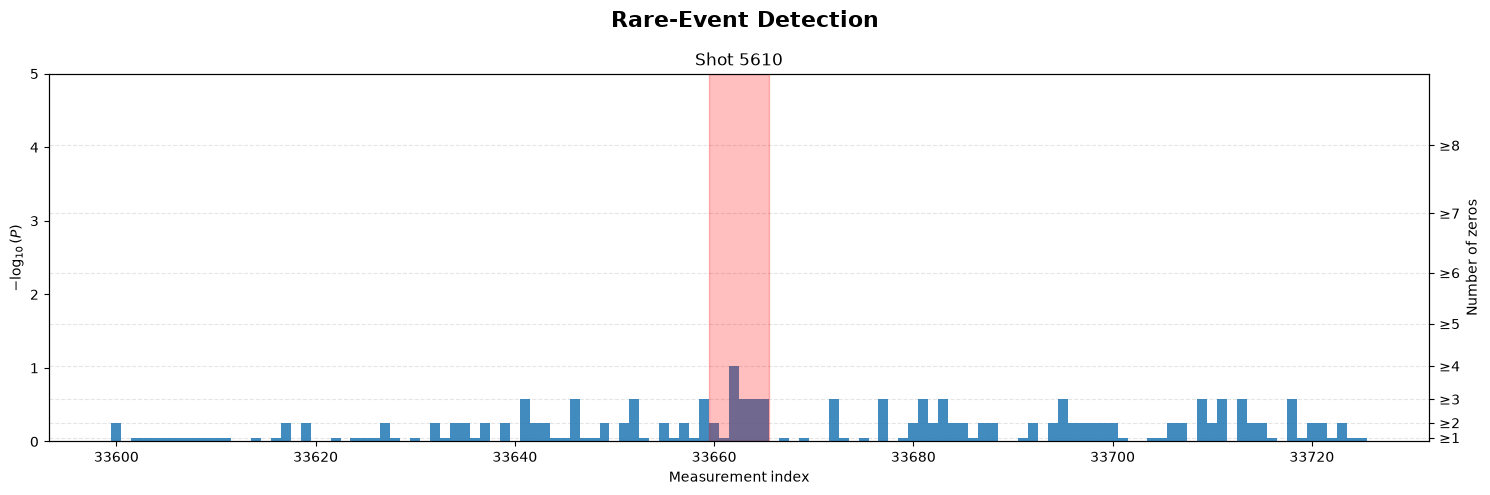

In [7]:
#plot against the probability model


plot_df = long_df.copy()

# Assign probability to each measurement according to
# the observed number of zeros
plot_df["probability"] = plot_df["num_zeros"].apply(
    lambda k: prob_tail[k]
)

# Rarity score
plot_df["rarity"] = -np.log10(
    np.clip(plot_df["probability"], 1e-15, None)
)

# Reference levels for the horizontal guide lines
rarity_levels = -np.log10(
    np.clip(prob_tail, 1e-15, None)
)


# Candidate rare event:
# expected fewer than ~1 per 1000 measurements
plot_df["unlikely"] = (
    plot_df["probability"] < 1e-3
)


# One subplot for each interesting event
fig, axes = plt.subplots(
    len(interesting_df),
    1,
    figsize=(15, 5 * len(interesting_df)),
    sharey=True,
)

if len(interesting_df) == 1:
    axes = [axes]

for ax, (_, event) in zip(axes, interesting_df.iterrows()):

    shot = event["shot"]

    # 10 shots before and after the candidate event to see surrounding shots as well
    first_shot = max(0, shot - 10)
    last_shot = min(df_last10.shape[0] - 1, shot + 10)

    subset = plot_df[
        (plot_df["shot"] >= first_shot) &
        (plot_df["shot"] <= last_shot)
    ].copy()

    for level in rarity_levels:
        ax.axhline(
            level,
            color="gray",
            linestyle="--",
            linewidth=0.8,
            alpha=0.2,
            zorder=0,
        )

    # Plot rarity
    ax.bar(
        subset["t"],
        subset["rarity"],
        width=1.0,
        alpha=0.85,
    )

    # Highlight the interesting shot
    shot_subset = subset[subset["shot"] == shot]

    ax.axvspan(
        shot_subset["t"].min() - 0.5,
        shot_subset["t"].max() + 0.5,
        color="red",
        alpha=0.25,
    )

    ax.set_title(f"Shot {shot}")
    ax.set_ylabel(r"$-\log_{10}(P)$")

    ax.set_title(f"Shot {shot}")

    ax.set_ylabel(r"$-\log_{10}(P)$")

    # Right-hand axis for K>=k labels
    ax_right = ax.twinx()

    ax.set_ylim(0, 5)
    ax_right.set_ylim(0, 5)

    ax_right.set_ylim(ax.get_ylim())
        
        # Skip K>=0 and only keep visible levels
    levels = rarity_levels[1:]
    labels = [f"≥{k}" for k in range(1, len(rarity_levels))]

    mask = levels <= 5  

    ax_right.set_yticks(levels[mask])
    ax_right.set_yticklabels(np.array(labels)[mask])
    
    ax_right.set_ylabel("Number of zeros")



fig.suptitle(
    "Rare-Event Detection",
    fontsize=16,
    fontweight="bold"
)

axes[-1].set_xlabel("Measurement index")
plt.tight_layout()

#to show the figure 
# plt.show()
